In [2]:
import streamlit as st
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
from PIL import Image

# Page Config
st.set_page_config(page_title="Fruit Freshness Detection", layout="centered")

st.title("🍎 Fruit Freshness Detection System 🍌")
st.write("Image upload karein aur freshness score check karein!")

# Load Trained Model
@st.cache_resource
def load_fruit_model():
    return load_model("best_fruit_model.h5")

model = load_fruit_model()

# Class Names (Apne dataset ke mutabiq order set karein)
class_names = ['freshapples', 'freshbanana', 'freshoranges', 'rottenapples', 'rottenbanana', 'rottenoranges']

# File Uploader Widget (No Path Error!)
uploaded_file = st.file_uploader("Fruit Photo Choose Karein...", type=["jpg", "jpeg", "png"])

if uploaded_file is not None:
    # Display Uploaded Image
    img = Image.open(uploaded_file)
    st.image(img, caption="Uploaded Image", use_column_width=True)
    
    # Preprocessing
    img_resized = img.resize((150, 150))
    img_array = image.img_to_array(img_resized)
    img_array = np.expand_dims(img_array, axis=0) / 255.0

    # Prediction Button
    if st.button("Check Freshness"):
        predictions = model.predict(img_array)[0]
        predicted_idx = np.argmax(predictions)
        label = class_names[predicted_idx]
        confidence = predictions[predicted_idx] * 100

        # Freshness Score Logic
        if "fresh" in label.lower():
            freshness_score = confidence
            status = "FRESH ✅"
        else:
            freshness_score = 100 - confidence
            status = "ROTTEN ❌"

        # Display Results
        st.subheader(f"Prediction: {label}")
        if status == "FRESH ✅":
            st.success(f"Status: {status} | Freshness Score: {freshness_score:.2f}%")
        else:
            st.error(f"Status: {status} | Freshness Score: {freshness_score:.2f}%")

2026-08-20 17:52:36.121 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-08-20 17:52:36.123 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-08-20 17:52:36.124 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-08-20 17:52:36.125 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-08-20 17:52:36.125 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-08-20 17:52:36.126 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-08-20 17:52:36.126 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-08-20 17:52:36.127 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar

2026-08-20 17:52:36.389 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-08-20 17:52:36.390 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-08-20 17:52:36.391 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-08-20 17:52:36.392 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-08-20 17:52:36.393 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


In [4]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt

# 1. Model Load Karein
model = load_model("best_fruit_model.h5")

# 2. Dataset ki Classes (Apne dataset folders ke exact order ke mutabiq)
class_names = ['freshapples', 'freshbanana', 'freshoranges', 'rottenapples', 'rottenbanana', 'rottenoranges']

# 3. Freshness Prediction Function
def predict_fruit_freshness(img_path):
    # Image loading and preprocessing
    img = image.load_img(img_path, target_size=(150, 150))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0) / 255.0

    # Prediction
    predictions = model.predict(img_array)[0]
    predicted_idx = np.argmax(predictions)
    label = class_names[predicted_idx]
    confidence = predictions[predicted_idx] * 100

    # Freshness Logic
    if "fresh" in label.lower():
        freshness_score = confidence
        status = "FRESH"
    else:
        freshness_score = 100 - confidence
        status = "ROTTEN"

    # Display Output Image with Result
    plt.figure(figsize=(5, 5))
    plt.imshow(image.load_img(img_path))
    plt.axis('off')
    plt.title(f"Class: {label}\nStatus: {status} ({freshness_score:.2f}% Fresh)", 
              fontsize=14, color='green' if status == "FRESH" else 'red')
    plt.show()

# -------------------------------------------------------------
# 4. Test Image Call (Path ke aage 'r' zaroor rakhein)
# -------------------------------------------------------------
predict_fruit_freshness("D:\fruite_freshness_detection\dataset\test\apple .jpeg")

<>:45: SyntaxWarning: invalid escape sequence '\d'
<>:45: SyntaxWarning: invalid escape sequence '\d'
C:\Users\DELL\AppData\Local\Temp\ipykernel_7772\3067676957.py:45: SyntaxWarning: invalid escape sequence '\d'
  predict_fruit_freshness("D:\fruite_freshness_detection\dataset\test\apple .jpeg")
C:\Users\DELL\AppData\Local\Temp\ipykernel_7772\3067676957.py:45: SyntaxWarning: invalid escape sequence '\d'
  predict_fruit_freshness("D:\fruite_freshness_detection\dataset\test\apple .jpeg")


OSError: [Errno 22] Invalid argument: 'D:\x0cruite_freshness_detection\\dataset\test\x07pple .jpeg'

In [5]:
import glob
import os

# Test dataset ke folder se automatically image dhoondne ke liye:
test_folder = r"D:\fruite_freshness_detection\dataset\test\*\*"
image_files = glob.glob(test_folder)

if len(image_files) > 0:
    # Auto-pick the first image from test folder
    sample_image = image_files[0]
    print(f"Testing File: {sample_image}")
    
    # Prediction Call
    predict_fruit_freshness(sample_image)
else:
    print("Test folder me koi images nahi mili! Path check karein.")

Testing File: D:\fruite_freshness_detection\dataset\test\apple\rotated_by_15_Screen Shot 2018-06-08 at 5.00.35 PM.png
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 427ms/step


C:\Users\DELL\AppData\Local\Temp\ipykernel_7772\3067676957.py:40: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [4]:
%matplotlib inline
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt

# Freshness Prediction Function (Updated for Interactive Plotting)
def predict_fruit_freshness(img_path):
    img = image.load_img(img_path, target_size=(150, 150))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0) / 255.0

    predictions = model.predict(img_array)[0]
    predicted_idx = np.argmax(predictions)
    label = class_names[predicted_idx]
    confidence = predictions[predicted_idx] * 100

    if "fresh" in label.lower():
        freshness_score = confidence
        status = "FRESH"
    else:
        freshness_score = 100 - confidence
        status = "ROTTEN"

    # Display Output
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.imshow(image.load_img(img_path))
    ax.axis('off')
    ax.set_title(f"Prediction: {label}\nStatus: {status} ({freshness_score:.2f}% Fresh)", 
                 fontsize=12, color='green' if status == "FRESH" else 'red')
    plt.show()

In [5]:
import glob

test_folder = r"D:\fruite_freshness_detection\dataset\test\*\*"
image_files = glob.glob(test_folder)

if image_files:
    # Multiple images test karne ke liye index badal sakte hain (e.g., image_files[1], image_files[2])
    sample_image = image_files[0] 
    print(f"Testing File: {sample_image}")
    predict_fruit_freshness(sample_image)

Testing File: D:\fruite_freshness_detection\dataset\test\apple\rotated_by_15_Screen Shot 2018-06-08 at 5.00.35 PM.png


NameError: name 'model' is not defined

Model Successfully Loaded!
Testing File: D:\fruite_freshness_detection\dataset\test\apple\rotated_by_15_Screen Shot 2018-06-08 at 5.00.35 PM.png
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 367ms/step


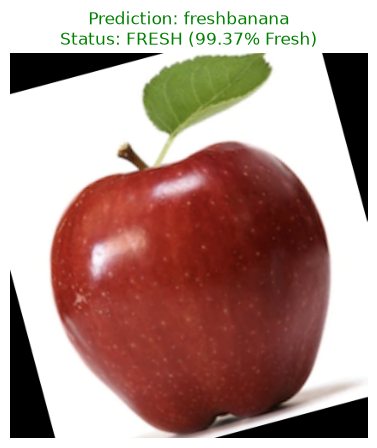

In [6]:
%matplotlib inline
import glob
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt

# 1. Load Trained H5 Model
model = load_model("best_fruit_model.h5")
print("Model Successfully Loaded!")

# 2. Define Dataset Class Names
class_names = ['freshapples', 'freshbanana', 'freshoranges', 'rottenapples', 'rottenbanana', 'rottenoranges']

# 3. Prediction Function
def predict_fruit_freshness(img_path):
    img = image.load_img(img_path, target_size=(150, 150))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0) / 255.0

    predictions = model.predict(img_array)[0]
    predicted_idx = np.argmax(predictions)
    label = class_names[predicted_idx]
    confidence = predictions[predicted_idx] * 100

    if "fresh" in label.lower():
        freshness_score = confidence
        status = "FRESH"
    else:
        freshness_score = 100 - confidence
        status = "ROTTEN"

    # Display Result
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.imshow(image.load_img(img_path))
    ax.axis('off')
    ax.set_title(f"Prediction: {label}\nStatus: {status} ({freshness_score:.2f}% Fresh)", 
                 fontsize=12, color='green' if status == "FRESH" else 'red')
    plt.show()

# 4. Find Test Image & Predict
test_folder = r"D:\fruite_freshness_detection\dataset\test\*\*"
image_files = glob.glob(test_folder)

if image_files:
    sample_image = image_files[0] # Alag image test karne ke liye index change karein (e.g., image_files[1])
    print(f"Testing File: {sample_image}")
    predict_fruit_freshness(sample_image)
else:
    print("Test folder me koi images nahi mili!")

Testing Orange: D:\fruite_freshness_detection\dataset\test\orange\rotated_by_15_Screen Shot 2018-06-12 at 11.50.41 PM.png
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step


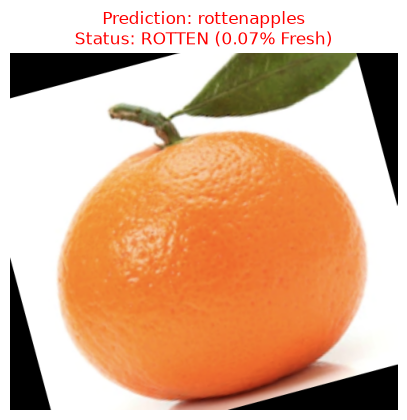

In [7]:
# 'oranges' ya 'orange' folder ki pehli image auto-select karne ke liye:
orange_files = glob.glob(r"D:\fruite_freshness_detection\dataset\test\*orange*\*")

if orange_files:
    sample_orange = orange_files[0]  # Dusri photo ke liye [1] ya [2] kar sakte hain
    print(f"Testing Orange: {sample_orange}")
    predict_fruit_freshness(sample_orange)
else:
    print("Orange folder me koi image nahi mili.")

In [10]:
predict_fruit_freshness("D:/fruite_freshness_detection/dataset/test/orenge .jpeg")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step


IndexError: list index out of range

In [14]:

print("hamare  Model Me Total Classes Hain:", model.output_shape[-1])

hamare  Model Me Total Classes Hain: 7


In [12]:
class_names = ['freshapples', 'freshbanana', 'freshoranges', 'rottenapples', 'rottenbanana', 'rottenoranges', 'other']

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step


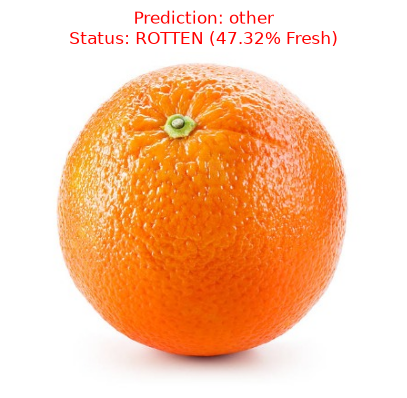

In [13]:
predict_fruit_freshness("D:/fruite_freshness_detection/dataset/test/orenge .jpeg")

In [17]:
predict_fruit_freshness("D:\fruite_freshness_detection\dataset\test\banana\banana .jpeg")

<>:1: SyntaxWarning: invalid escape sequence '\d'
<>:1: SyntaxWarning: invalid escape sequence '\d'
C:\Users\DELL\AppData\Local\Temp\ipykernel_27944\3879641808.py:1: SyntaxWarning: invalid escape sequence '\d'
  predict_fruit_freshness("D:\fruite_freshness_detection\dataset\test\banana\banana .jpeg")
C:\Users\DELL\AppData\Local\Temp\ipykernel_27944\3879641808.py:1: SyntaxWarning: invalid escape sequence '\d'
  predict_fruit_freshness("D:\fruite_freshness_detection\dataset\test\banana\banana .jpeg")


OSError: [Errno 22] Invalid argument: 'D:\x0cruite_freshness_detection\\dataset\test\x08anana\x08anana .jpeg'